In [1]:
# 🧩 Import required libraries
# pandas: for data manipulation and analysis
import pandas as pd

# re: regular expressions library, used for text cleaning
import re

# matplotlib.pyplot and seaborn: libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

1️⃣ Load and Parse the Dataset

In [2]:
# 🔍 Load raw CSV content into a single string
with open('week5_customer_reviews.csv', 'r', encoding='utf-8') as f:
    raw_data = f.read()

# 🧹 Clean up extra whitespace and split into records
# Each record seems to end with double commas: ',,'
raw_records = raw_data.split(',,')

# 📦 Initialize list to store cleaned records
cleaned_records = []

# Loop through each raw record
for record in raw_records:
    record = record.strip()  # Remove leading/trailing spaces
    if record:  # Skip empty strings
        parts = record.split(',')  # Split by comma to get fields
        if len(parts) >= 6:  # Ensure there are enough fields (ID, Name, Review, Product, Rating, Date)
            # Store relevant parts in dictionary format
            cleaned_records.append({
                'review_id': parts[0],
                'customer_name': parts[1],
                'raw_review': ','.join(parts[2:-3]),  # Join in case of commas inside review
                'product': parts[-3],
                'rating': int(parts[-2]),
                'date': parts[-1]
            })

# 📋 Convert list of dictionaries into a DataFrame
df = pd.DataFrame(cleaned_records)

# Show first few rows of the DataFrame
print("First few rows of raw parsed data:")
df.head()

First few rows of raw parsed data:


,review_id,customer_name,raw_review,product,rating,date
0,review_id,customer_name,"raw_review,product,rating,date,cleaned_review,...",Toaster,3,2025-05-31
1,2,Brian Coleman,Hair emplo\(yee on.,Smartwatch,3,2025-06-02
2,3,Jeremy Price,Five p~{}#layer rest himself.,Smartwatch,4,2025-05-01
3,4,Jose Roth,"""Off try shake care health nation identify mod...",Phone Case,5,2025-05-17
4,5,Allen Sims,"""New m~,(!🗑@!:~y sport management outside cent...",Headphones,3,2025-05-19


2️⃣ Clean the Review Text

In [5]:
# 🧼 Define cleaning function
def clean_review(text):
    """
    Cleans a given review text by:
    - Removing emojis
    - Removing special characters and digits
    - Lowercasing and trimming extra spaces
    """
    
    # Emoji removal pattern (Unicode ranges for emoji blocks)
    emoji_pattern = re.compile(
        "["
        u"\U0001F600-\U0001F64F"  # emoticons
        u"\U0001F300-\U0001F5FF"  # symbols & pictographs
        u"\U0001F680-\U0001F6FF"  # transport & map symbols
        u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
        "]+", flags=re.UNICODE)
    
    text = emoji_pattern.sub(r'', text)  # Replace emojis with empty string
    
    # Remove all non-letter characters and digits
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Lowercase and trim extra spaces
    text = text.lower().strip()
    
    return text

# 🔁 Apply cleaning function to create new column: cleaned_review
df['cleaned_review'] = df['raw_review'].apply(clean_review)

3️⃣ Create New Columns

3.1 Review Length (Number of Words)

In [6]:
# 🧮 Count words in each cleaned review
# We use .split() to split on spaces, then len() to count words
df['review_length'] = df['cleaned_review'].apply(lambda x: len(x.split()))

3.2 Sentiment Based on Rating

In [9]:
# 😊😐😠 Categorize based on rating
def get_sentiment(rating):
    """
    Converts numeric rating into sentiment categories:
    - Positive: 4 or 5
    - Neutral: 3
    - Negative: 1 or 2
    """
    if rating >= 4:
        return 'Positive'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Negative'

# Apply the sentiment function to the rating column
df['sentiment'] = df['rating'].apply(get_sentiment)

4️⃣ Summary and Insights

4.1 Unique Products Reviewed

In [10]:
# 📐 Count unique products
unique_products = df['product'].nunique()
print(f"Unique products reviewed: {unique_products}")

# Print the list of product names and how many reviews each has
print("\nProduct list with review counts:")
print(df['product'].value_counts())

Unique products reviewed: 7

Product list with review counts:
product
Headphones    732
Shoes         730
Mug           718
Blender       711
Phone Case    700
Smartwatch    694
Toaster       692
Name: count, dtype: int64


4.2 Average Review Length by Sentiment


Average review length by sentiment:
sentiment
Negative    9.647117
Neutral     9.458416
Positive    9.529923
Name: review_length, dtype: float64


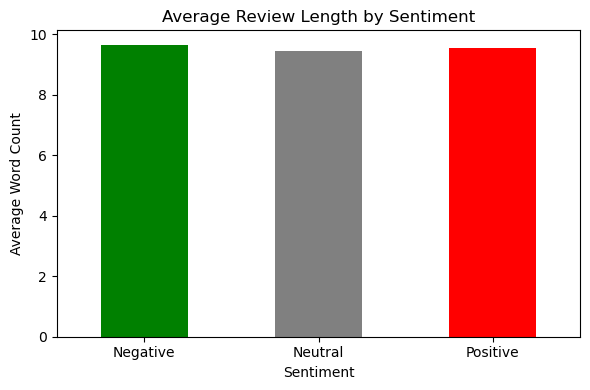

In [11]:
# 📊 Group by sentiment and calculate average word count
avg_lengths = df.groupby('sentiment')['review_length'].mean()
print("\nAverage review length by sentiment:")
print(avg_lengths)

# 📈 Plot bar chart
plt.figure(figsize=(6, 4))
avg_lengths.plot(kind='bar', color=['green', 'gray', 'red'], title='Average Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Word Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

4.3 Product with Most Negative Reviews

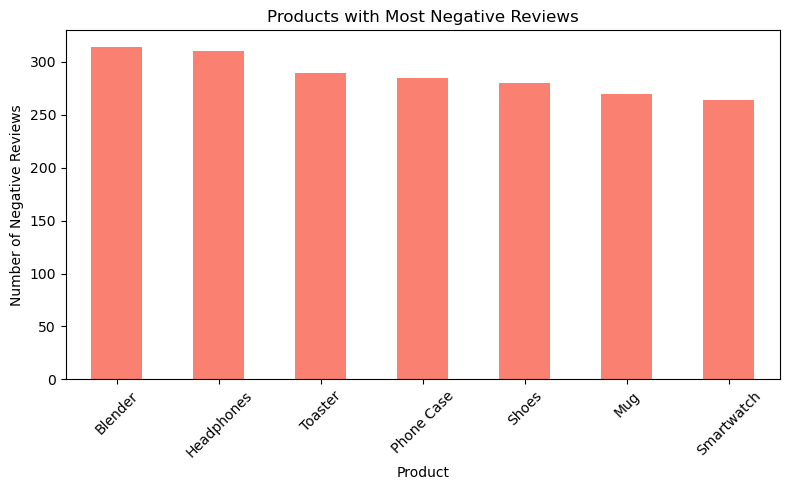


Product with most negative reviews: Blender


In [12]:
# ❌ Filter negative reviews only
negative_reviews = df[df['sentiment'] == 'Negative']

# 📊 Count number of negative reviews per product
product_neg_counts = negative_reviews['product'].value_counts()

# 📈 Bar plot
plt.figure(figsize=(8, 5))
product_neg_counts.plot(kind='bar', title='Products with Most Negative Reviews', color='salmon')
plt.xlabel('Product')
plt.ylabel('Number of Negative Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 🔥 Find and print the product with the most negative reviews
most_negative_product = product_neg_counts.idxmax()
print(f"\nProduct with most negative reviews: {most_negative_product}")

4.4 Number of Reviews per Product

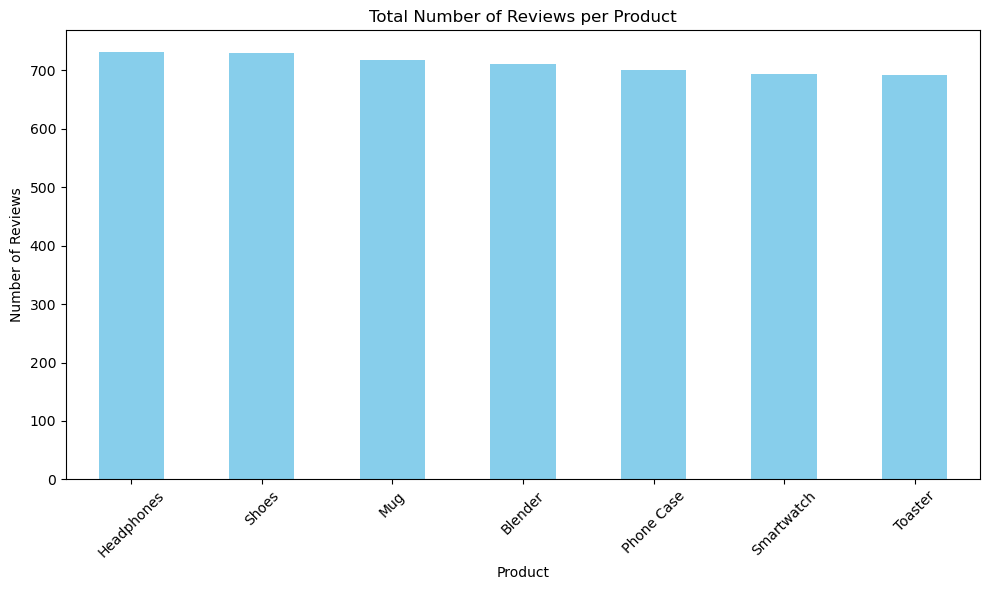

In [13]:
# 📊 Count total reviews per product
product_review_counts = df['product'].value_counts()

# 📈 Bar chart
plt.figure(figsize=(10, 6))
product_review_counts.plot(kind='bar', title='Total Number of Reviews per Product', color='skyblue')
plt.xlabel('Product')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
df.head()

,review_id,customer_name,raw_review,product,rating,date,cleaned_review,review_length,sentiment
0,review_id,customer_name,"raw_review,product,rating,date,cleaned_review,...",Toaster,3,2025-05-31,rawreviewproductratingdatecleanedreviewreviewl...,17,Neutral
1,2,Brian Coleman,Hair emplo\(yee on.,Smartwatch,3,2025-06-02,hair employee on,3,Neutral
2,3,Jeremy Price,Five p~{}#layer rest himself.,Smartwatch,4,2025-05-01,five player rest himself,4,Positive
3,4,Jose Roth,"""Off try shake care health nation identify mod...",Phone Case,5,2025-05-17,off try shake care health nation identify mode...,19,Positive
4,5,Allen Sims,"""New m~,(!🗑@!:~y sport management outside cent...",Headphones,3,2025-05-19,new my sport management outside center age opt...,19,Neutral


In [16]:
df = df.drop(0)

In [17]:
df.head()

,review_id,customer_name,raw_review,product,rating,date,cleaned_review,review_length,sentiment
1,2,Brian Coleman,Hair emplo\(yee on.,Smartwatch,3,2025-06-02,hair employee on,3,Neutral
2,3,Jeremy Price,Five p~{}#layer rest himself.,Smartwatch,4,2025-05-01,five player rest himself,4,Positive
3,4,Jose Roth,"""Off try shake care health nation identify mod...",Phone Case,5,2025-05-17,off try shake care health nation identify mode...,19,Positive
4,5,Allen Sims,"""New m~,(!🗑@!:~y sport management outside cent...",Headphones,3,2025-05-19,new my sport management outside center age opt...,19,Neutral
5,6,Aaron Castro,He happy red 🔥:$.former rate manage.,Toaster,2,2025-06-06,he happy red former rate manage,6,Negative


In [18]:
df.to_csv('week5_final_csv_dataset.csv', index=False)